# Day 09: LLM Discourse – Topics & Sentiment

**Goal:** analyse tweets about Large Language Models (ChatGPT etc.) to find:
1. **What** people talk about (topic modelling with BERTopic, topics named by an LLM)
2. **How** they feel (sentiment with a Twitter RoBERTa model)
3. **How** this changes over time, and how **popular accounts** differ from **average users**

**Before running:** Runtime → Change runtime type → **T4 GPU** → Save. Then **Runtime → Run all**.

## 0. Install and import

In [1]:
!pip install -q bertopic

import os, re, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import kagglehub

device_name = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device_name)
sns.set_style("whitegrid")

Using: cuda


## 1. Load the dataset
ChatGPT tweets collected daily from the Twitter API (public tweets). The columns we need: tweet text, date, follower counts and engagement (likes, retweets, replies, impressions).

In [2]:
path = kagglehub.dataset_download("edomingo/chatgpt-1000-daily-tweets")
csv_file = glob.glob(f"{path}/**/*.csv", recursive=True)[0]
raw = pd.read_csv(csv_file)
print("Rows, columns:", raw.shape)
print(list(raw.columns))

Using Colab cache for faster access to the 'chatgpt-1000-daily-tweets' dataset.
Rows, columns: (66375, 20)
['tweet_id', 'tweet_created', 'tweet_extracted', 'text', 'lang', 'user_id', 'user_name', 'user_username', 'user_location', 'user_description', 'user_created', 'user_followers_count', 'user_following_count', 'user_tweet_count', 'user_verified', 'source', 'retweet_count', 'like_count', 'reply_count', 'impression_count']


## 2. Text preprocessing
- Keep **English** tweets only (the models work best in English).
- Remove **retweets** ("RT @...") and **duplicate** texts (spam bots), so one viral tweet is not counted hundreds of times.
- Clean text for topic modelling: remove links, @mentions, emojis and symbols; keep hashtag words and AI keywords (GPT-4, ChatGPT).
- Remove very short tweets (< 4 words).
- **Privacy:** personal columns (names, usernames, locations, descriptions) are dropped. Only aggregate statistics are reported.

In [3]:
df = raw.copy()
print("Start:", len(df))
df = df[df["lang"] == "en"]
print("English only:", len(df))
df = df[~df["text"].astype(str).str.startswith("RT @")]
print("Without retweets:", len(df))
df = df.drop_duplicates(subset="text")
print("Without duplicates:", len(df))

def clean_tweet(t):
    t = re.sub(r"http\S+|www\.\S+", " ", str(t))
    t = re.sub(r"@\w+", " ", t)
    t = t.replace("#", " ")
    t = re.sub(r"&amp;", " and ", t)
    t = re.sub(r"[^A-Za-z0-9\s\-\.\,\!\?\']", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean_text"] = df["text"].apply(clean_tweet)
df = df[df["clean_text"].str.split().str.len() >= 4]
print("Without very short tweets:", len(df))

df["date"] = pd.to_datetime(df["tweet_created"], errors="coerce").dt.tz_localize(None)
for c in ["user_followers_count", "like_count", "retweet_count", "reply_count", "impression_count"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0)

# Privacy: drop personal columns we don't need
df = df.drop(columns=["user_name", "user_username", "user_location", "user_description"], errors="ignore")
df = df.dropna(subset=["date"]).reset_index(drop=True)

print("\nFinal tweets:", len(df))
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())

Start: 66375
English only: 20545
Without retweets: 7389
Without duplicates: 6981
Without very short tweets: 6673

Final tweets: 6673
Date range: 2023-04-03 to 2023-05-12


## 3. Topic modelling (BERTopic)
1. Each tweet becomes an **embedding** (numbers that hold its meaning) with a small Sentence-Transformer.
2. **UMAP** simplifies the embeddings, **HDBSCAN** groups similar tweets (it finds the number of topics itself; tweets that fit no group become outliers, topic -1).
3. **c-TF-IDF** finds each group's most distinctive words.

Very common words (chatgpt, ai, openai...) are ignored when naming topics, because they appear in almost every tweet.

In [4]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from umap import UMAP

docs = df["clean_text"].tolist()
embedder = SentenceTransformer("all-MiniLM-L6-v2", device=device_name)
embeddings = embedder.encode(docs, show_progress_bar=True, batch_size=128)

extra_stop = ["chatgpt", "gpt", "ai", "openai", "just", "like", "use", "using", "new",
              "amp", "chat", "don", "ve", "ll", "know", "think", "make"]
vectorizer = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS) + extra_stop,
                             ngram_range=(1, 2), min_df=5)
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine",
                  random_state=42)   # fixed seed → same topics every run

topic_model = BERTopic(umap_model=umap_model, vectorizer_model=vectorizer,
                       min_topic_size=40, verbose=True)
topics, _ = topic_model.fit_transform(docs, embeddings)
df["topic"] = topics

info = topic_model.get_topic_info()
print("Topics found:", len(info) - 1)
info[["Topic", "Count", "Name"]]

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/53 [00:00<?, ?it/s]

2026-11-01 10:15:17,328 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-01 10:16:15,521 - BERTopic - Dimensionality - Completed ✓
2026-11-01 10:16:15,522 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-01 10:16:15,947 - BERTopic - Cluster - Completed ✓
2026-11-01 10:16:15,955 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-01 10:16:16,191 - BERTopic - Representation - Completed ✓


Topics found: 16


,Topic,Count,Name
0,-1,1181,-1_code_language_free_crypto
1,0,3265,0_write_asked_ask_prompt
2,1,743,1_intelligence_tools_artificial_artificial int...
3,2,251,2_tiktok_discussing_army_night
4,3,214,3_gpt4_35_better_llm
5,4,168,4_shopping_premium_plus_pro
6,5,122,5_openais_api_data_privacy
7,6,107,6_low_aipowered_hey_lot
8,7,97,7_amazon_zoom_turnitin_disney
9,8,89,8_study_responses_health_questions


## 4. Naming topics with an LLM
For each topic, the LLM receives the **top 8 keywords** and **5 example tweets** and returns a short name.
Example tweets matter: keywords alone can mislead (e.g. "code" can mean a discount code, not programming).

Uses Colab's built-in **Gemini** if available, otherwise a small local model (Qwen2.5-1.5B-Instruct).

In [5]:
try:
    from google.colab import ai
    ai.generate_text("Say OK")
    def ask_llm(prompt):
        return ai.generate_text(prompt)
    llm_name = "Gemini (Colab built-in)"
except Exception:
    from transformers import pipeline
    gen = pipeline("text-generation", model="Qwen/Qwen2.5-1.5B-Instruct", device_map="auto")
    def ask_llm(prompt):
        out = gen([{"role": "user", "content": prompt}], max_new_tokens=20, do_sample=False)
        return out[0]["generated_text"][-1]["content"]
    llm_name = "Qwen2.5-1.5B-Instruct (local)"
print("Using LLM:", llm_name)

labels = {}
for t in sorted(df["topic"].unique()):
    if t == -1:
        labels[t] = "Outliers (no clear topic)"
        continue
    keywords = ", ".join([w for w, _ in topic_model.get_topic(t)[:8]])
    n = min(5, int((df["topic"] == t).sum()))
    sample = df.loc[df["topic"] == t, "clean_text"].sample(n=n, random_state=42)
    examples = "\n".join("- " + d[:200] for d in sample)
    prompt = f"""These tweets about ChatGPT/LLMs belong to one topic.
Keywords: {keywords}
Example tweets:
{examples}

Give this topic a short, clear name of 2 to 5 words. Reply with ONLY the name."""
    try:
        name = ask_llm(prompt).strip().strip('"').split("\n")[0]
    except Exception:
        name = topic_model.get_topic_info().set_index("Topic").loc[t, "Name"]
    labels[t] = name
    print(f"Topic {t:2d} ({(df['topic'] == t).sum():4d} tweets): {name}")

df["topic_label"] = df["topic"].map(labels)

Using LLM: Gemini (Colab built-in)
Topic  0 (3265 tweets): ChatGPT Prompting and Usage
Topic  1 ( 743 tweets): Future of Artificial Intelligence
Topic  2 ( 251 tweets): World News and Current Events
Topic  3 ( 214 tweets): GPT-4 Capabilities and Comparisons
Topic  4 ( 168 tweets): Premium Account Sales
Topic  5 ( 122 tweets): OpenAI API and Data Privacy
Topic  6 ( 107 tweets): AI Crypto Token Promotions
Topic  7 (  97 tweets): Premium Account Sales
Topic  8 (  89 tweets): ChatGPT in Healthcare
Topic  9 (  87 tweets): ChatGPT Data Privacy Bans
Topic 10 (  74 tweets): Twitter Content Creation
Topic 11 (  65 tweets): Referral Codes and Promotions
Topic 12 (  61 tweets): ChatGPT for Business
Topic 13 (  57 tweets): Premium Account Sales
Topic 14 (  51 tweets): Google Bard vs ChatGPT
Topic 15 (  41 tweets): Microsoft Bing AI Search


## 5. Sentiment analysis (Twitter RoBERTa)
`cardiffnlp/twitter-roberta-base-sentiment-latest` was trained on ~124M tweets, so it understands short, informal tweet language. Used as-is (no training).

The model was trained with "@user" and "http" placeholders, so the **original** text is prepared that way (emojis are kept, because they carry emotion).

In [6]:
from transformers import pipeline

sent_model = pipeline("sentiment-analysis",
                      model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                      device=0 if device_name == "cuda" else -1,
                      truncation=True, max_length=128)

def prep_for_roberta(t):
    t = re.sub(r"@\w+", "@user", str(t))
    return re.sub(r"http\S+", "http", t)

start = time.time()
res = sent_model(df["text"].apply(prep_for_roberta).tolist(), batch_size=32)
print(f"Sentiment done in {(time.time() - start)/60:.1f} min")

df["sentiment"] = [r["label"].lower() for r in res]
df["sentiment_score"] = [r["score"] for r in res]

print("\nOverall sentiment (%):")
print((df["sentiment"].value_counts(normalize=True) * 100).round(1))

for s in ["positive", "neutral", "negative"]:
    for _, r in df[df["sentiment"] == s].sample(2, random_state=1).iterrows():
        print(f"\n[{s.upper()} {r['sentiment_score']:.2f}] {r['clean_text'][:140]}")

# Save a checkpoint (so a Colab restart doesn't lose the slow work)
df.to_csv("tweets_with_topics_sentiment.csv", index=False)
print("\nSaved tweets_with_topics_sentiment.csv")

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Sentiment done in 0.6 min

Overall sentiment (%):
sentiment
neutral     49.6
positive    31.9
negative    18.6
Name: proportion, dtype: float64

[POSITIVE 0.73] I asked ChatGPT his conception of the creation of humanity . A cosmic whisper birthed humanity, echoing divine origins within us. Let's embr

[POSITIVE 0.55] ChatGPT will make you superhuman. But most people don t know the best ways to use AI That's why I built this free document for you 1000 Best

[NEUTRAL 0.77] Discussing the latest episode of ONEPIECE on ChatGPT during Ramadan Kareem in China, feels like finding Queen on Laylatul Qadr.

[NEUTRAL 0.93] Global AGI, DARPA Reverse Engineering, Robots and GPT4, MidJourney Deep Fa... via

[NEGATIVE 0.77] Did you not hear? All the writers and decision makers were sacked from Netflix and ChatGPT does it all now

[NEGATIVE 0.46] For good reason. It was ChatGPT nonsense. Should have verified elsewhere. I appreciate the correction.

Saved tweets_with_topics_sentiment.csv


## 6. Results and charts

### 6a. Topic sizes

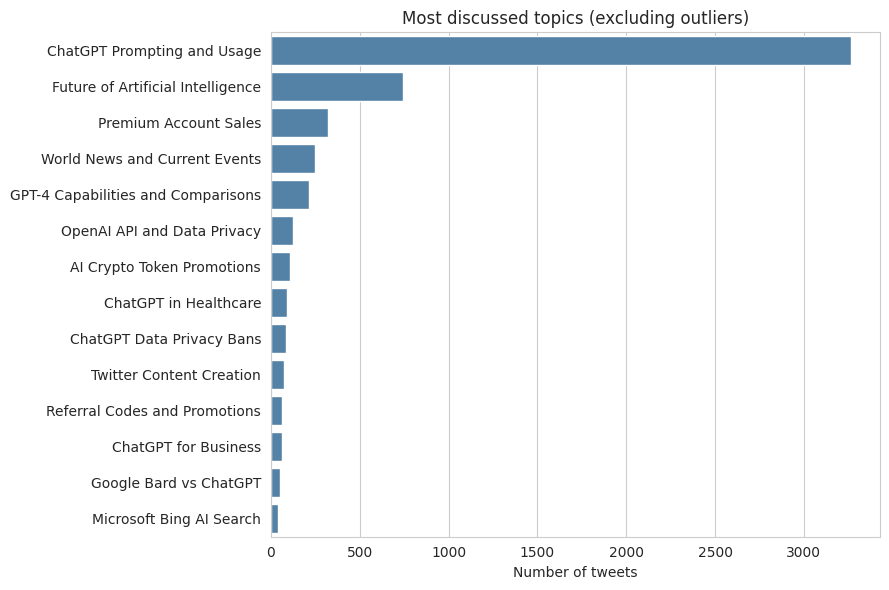

In [7]:
topic_counts = df[df["topic"] != -1]["topic_label"].value_counts().head(15)
plt.figure(figsize=(9, 6))
sns.barplot(x=topic_counts.values, y=topic_counts.index, color="steelblue")
plt.title("Most discussed topics (excluding outliers)")
plt.xlabel("Number of tweets"); plt.ylabel("")
plt.tight_layout(); plt.show()

### 6b. Sentiment per topic

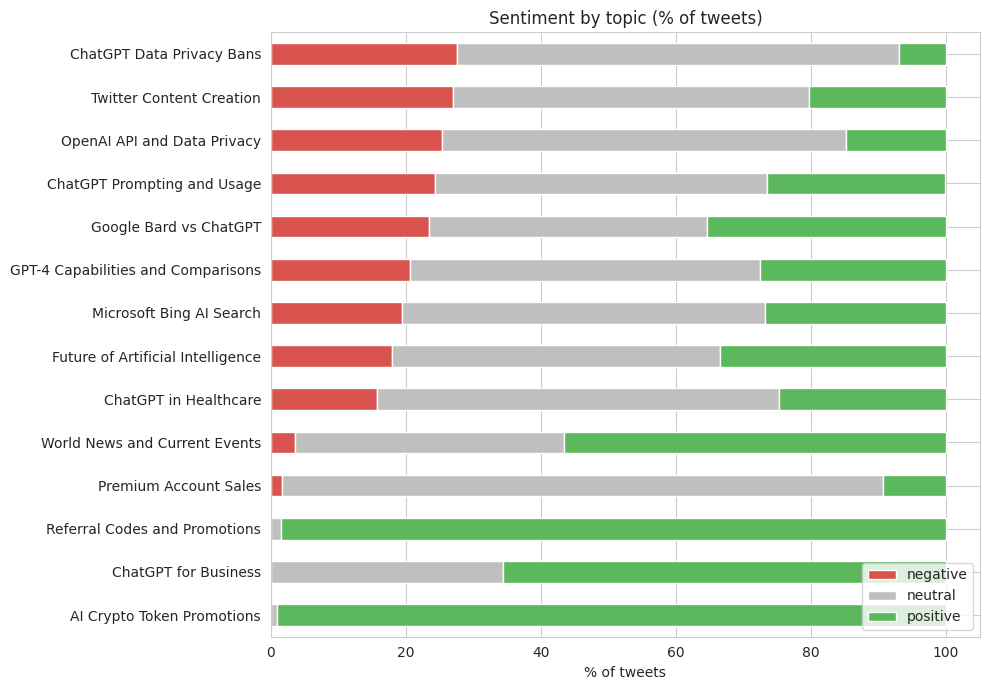

sentiment,negative,neutral,positive
topic_label,,,
ChatGPT Data Privacy Bans,27.6,65.5,6.9
Twitter Content Creation,27.0,52.7,20.3
OpenAI API and Data Privacy,25.4,59.8,14.8
ChatGPT Prompting and Usage,24.3,49.3,26.3
Google Bard vs ChatGPT,23.5,41.2,35.3
GPT-4 Capabilities and Comparisons,20.6,51.9,27.6
Microsoft Bing AI Search,19.5,53.7,26.8
Future of Artificial Intelligence,17.9,48.6,33.5
ChatGPT in Healthcare,15.7,59.6,24.7


In [8]:
by_topic = (pd.crosstab(df["topic_label"], df["sentiment"], normalize="index") * 100).round(1)
by_topic = by_topic.drop(index="Outliers (no clear topic)", errors="ignore")
by_topic = by_topic.reindex(columns=["negative", "neutral", "positive"], fill_value=0)
by_topic = by_topic.sort_values("negative")

by_topic.plot(kind="barh", stacked=True, figsize=(10, 7),
              color=["#d9534f", "#bfbfbf", "#5cb85c"])
plt.title("Sentiment by topic (% of tweets)")
plt.xlabel("% of tweets"); plt.ylabel("")
plt.legend(loc="lower right")
plt.tight_layout(); plt.show()
by_topic.sort_values("negative", ascending=False)

### 6c. Sentiment over time
Daily share of each sentiment, smoothed with a 3-day rolling average to reduce day-to-day noise.

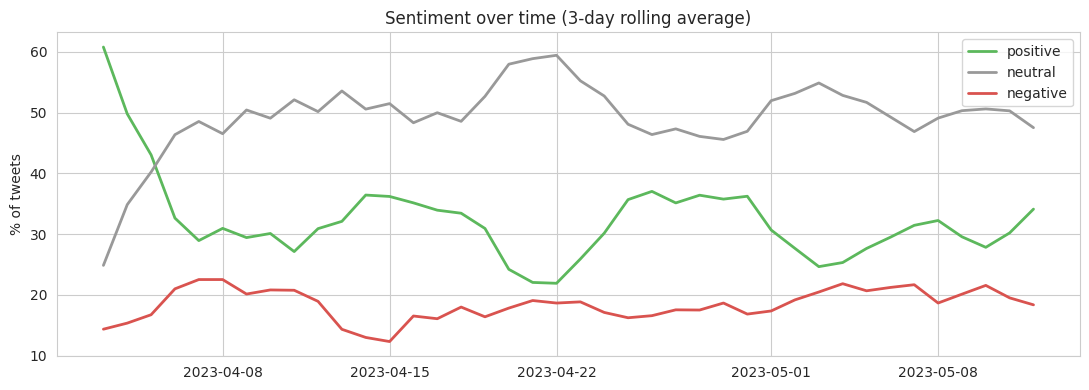

Tweets per day: min 108 | median 165 | max 291


In [9]:
daily = (pd.crosstab(df["date"].dt.date, df["sentiment"], normalize="index") * 100)
daily = daily.reindex(columns=["negative", "neutral", "positive"], fill_value=0)
daily.index = pd.to_datetime(daily.index)
smooth = daily.rolling(3, min_periods=1).mean()

plt.figure(figsize=(11, 4))
for s, c in [("positive", "#5cb85c"), ("neutral", "#999999"), ("negative", "#d9534f")]:
    plt.plot(smooth.index, smooth[s], label=s, color=c, linewidth=2)
plt.title("Sentiment over time (3-day rolling average)")
plt.ylabel("% of tweets"); plt.legend()
plt.tight_layout(); plt.show()

tweets_per_day = df.groupby(df["date"].dt.date).size()
print("Tweets per day: min", tweets_per_day.min(), "| median", int(tweets_per_day.median()),
      "| max", tweets_per_day.max())

### 6d. Popular accounts vs average users
"Popular" = top 10% of accounts by follower count. We compare what they talk about, how they feel, and the engagement their tweets get.

Popular = 5,137+ followers
account_type
Average              6005
Popular (top 10%)     668
Name: count, dtype: int64


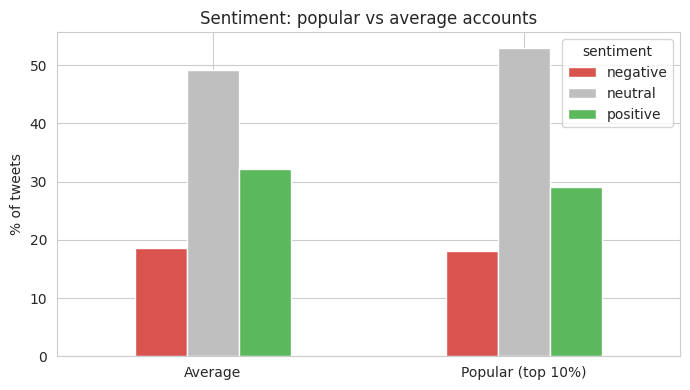

sentiment          negative  neutral  positive
account_type                                  
Average                18.6     49.2      32.2
Popular (top 10%)      18.0     53.0      29.0


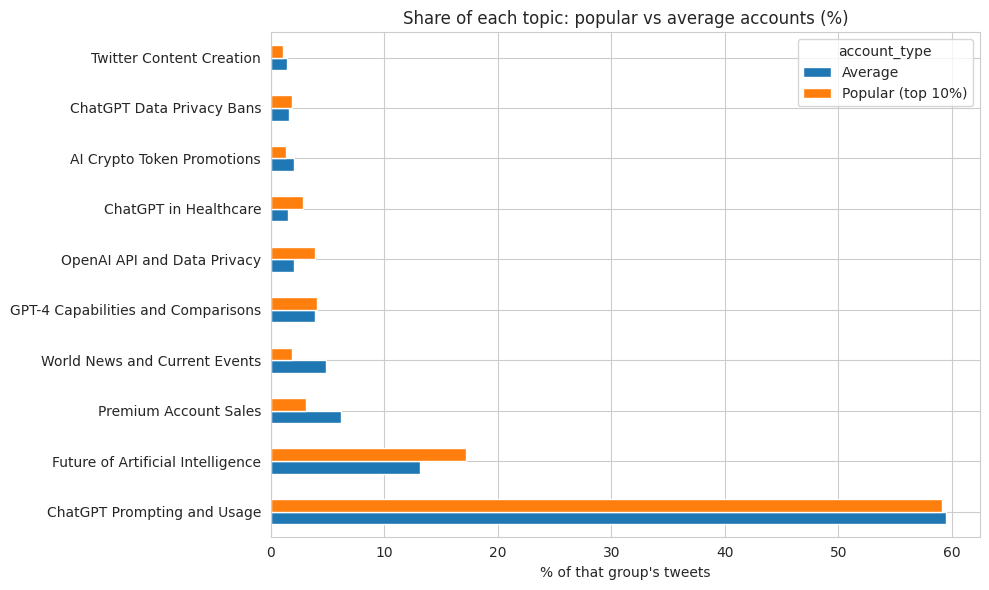


Median engagement per tweet:
                   like_count  retweet_count  reply_count  impression_count
account_type                                                               
Average                   0.0            0.0          0.0              27.0
Popular (top 10%)         1.0            0.0          0.0              89.5


In [10]:
cut = df["user_followers_count"].quantile(0.90)
df["account_type"] = np.where(df["user_followers_count"] >= cut, "Popular (top 10%)", "Average")
print(f"Popular = {int(cut):,}+ followers")
print(df["account_type"].value_counts())

# Sentiment by account type
acc_sent = (pd.crosstab(df["account_type"], df["sentiment"], normalize="index") * 100).round(1)
acc_sent = acc_sent.reindex(columns=["negative", "neutral", "positive"], fill_value=0)
acc_sent.plot(kind="bar", figsize=(7, 4), color=["#d9534f", "#bfbfbf", "#5cb85c"], rot=0)
plt.title("Sentiment: popular vs average accounts")
plt.ylabel("% of tweets"); plt.xlabel("")
plt.tight_layout(); plt.show()
print(acc_sent)

# Top topics by account type
acc_topic = (pd.crosstab(df[df["topic"] != -1]["topic_label"],
                         df[df["topic"] != -1]["account_type"], normalize="columns") * 100).round(1)
top = acc_topic.max(axis=1).sort_values(ascending=False).head(10).index
acc_topic.loc[top].plot(kind="barh", figsize=(10, 6))
plt.title("Share of each topic: popular vs average accounts (%)")
plt.xlabel("% of that group's tweets"); plt.ylabel("")
plt.tight_layout(); plt.show()

# Engagement (medians are used because a few viral tweets would distort averages)
eng = df.groupby("account_type")[["like_count", "retweet_count", "reply_count", "impression_count"]].median()
print("\nMedian engagement per tweet:")
print(eng)

### 6e. Engagement by sentiment

Average engagement by sentiment:
           like_count  retweet_count  impression_count
sentiment                                             
negative         17.8            2.1            2192.0
neutral           7.2            1.3            1342.6
positive          8.0            1.4            1806.8


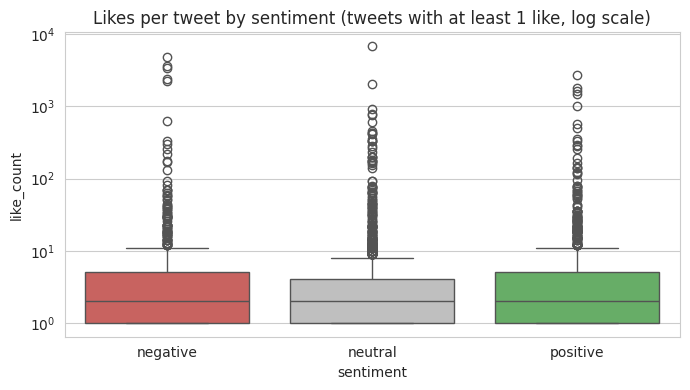

In [11]:
eng_sent = df.groupby("sentiment")[["like_count", "retweet_count", "impression_count"]].mean().round(1)
eng_sent = eng_sent.reindex(["negative", "neutral", "positive"])
print("Average engagement by sentiment:")
print(eng_sent)

plt.figure(figsize=(7, 4))
sns.boxplot(data=df[df["like_count"] > 0], x="sentiment", y="like_count",
            order=["negative", "neutral", "positive"],
            palette={"negative": "#d9534f", "neutral": "#bfbfbf", "positive": "#5cb85c"})
plt.yscale("log")
plt.title("Likes per tweet by sentiment (tweets with at least 1 like, log scale)")
plt.tight_layout(); plt.show()

## 7. Save results

In [12]:
df.to_csv("tweets_with_topics_sentiment.csv", index=False)
topic_summary = (df.groupby(["topic", "topic_label"]).size().rename("tweets").reset_index()
                 .merge(by_topic.reset_index().rename(columns={"index": "topic_label"}),
                        on="topic_label", how="left"))
topic_summary.to_csv("topic_summary.csv", index=False)
print("Saved: tweets_with_topics_sentiment.csv, topic_summary.csv")
topic_summary.sort_values("tweets", ascending=False)

Saved: tweets_with_topics_sentiment.csv, topic_summary.csv


,topic,topic_label,tweets,negative,neutral,positive
1,0,ChatGPT Prompting and Usage,3265,24.3,49.3,26.3
0,-1,Outliers (no clear topic),1181,NaN,NaN,NaN
2,1,Future of Artificial Intelligence,743,17.9,48.6,33.5
3,2,World News and Current Events,251,3.6,39.8,56.6
4,3,GPT-4 Capabilities and Comparisons,214,20.6,51.9,27.6
5,4,Premium Account Sales,168,1.6,89.1,9.3
6,5,OpenAI API and Data Privacy,122,25.4,59.8,14.8
7,6,AI Crypto Token Promotions,107,0.0,0.9,99.1
8,7,Premium Account Sales,97,1.6,89.1,9.3
9,8,ChatGPT in Healthcare,89,15.7,59.6,24.7


### Popular vs average accounts
- Popular accounts = top 10% by followers (5,137+): 668 tweets; average accounts: 6,005 tweets.
- Sentiment is very similar: popular accounts are slightly more neutral (53% vs 49%), likely because they share news and updates; average users are slightly more positive (32% vs 29%), often sharing personal experiences.
- Typical engagement is very low: the median average-account tweet gets 0 likes and 27 impressions. Popular accounts get ~3x more impressions (89.5).

### Engagement by sentiment
- Negative tweets received the most engagement on average (17.8 likes vs 7–8 for neutral/positive, and the most impressions), consistent with a "negativity bias".
- These are averages and may be driven by a few viral tweets; medians/boxplot should be checked before drawing strong conclusions.